
# Predictive Modeling Using Machine Learning

## Breast Cancer Classification

This project uses machine learning algorithms to predict whether a breast tumour is benign or malignant.

### Algorithms Used
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC Curve
- AUC Score




In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

df['target'] = cancer.target

print("First five rows of the dataset:")
display(df.head())


First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nTarget Distribution:")
print(df['target'].value_counts())


Dataset Shape: (569, 31)

Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Missing Values:
0

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64


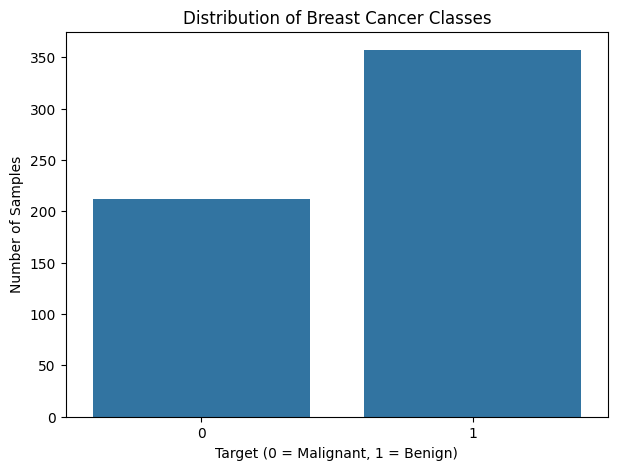

In [4]:

plt.figure(figsize=(7, 5))

sns.countplot(x='target', data=df)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Target (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")

plt.show()


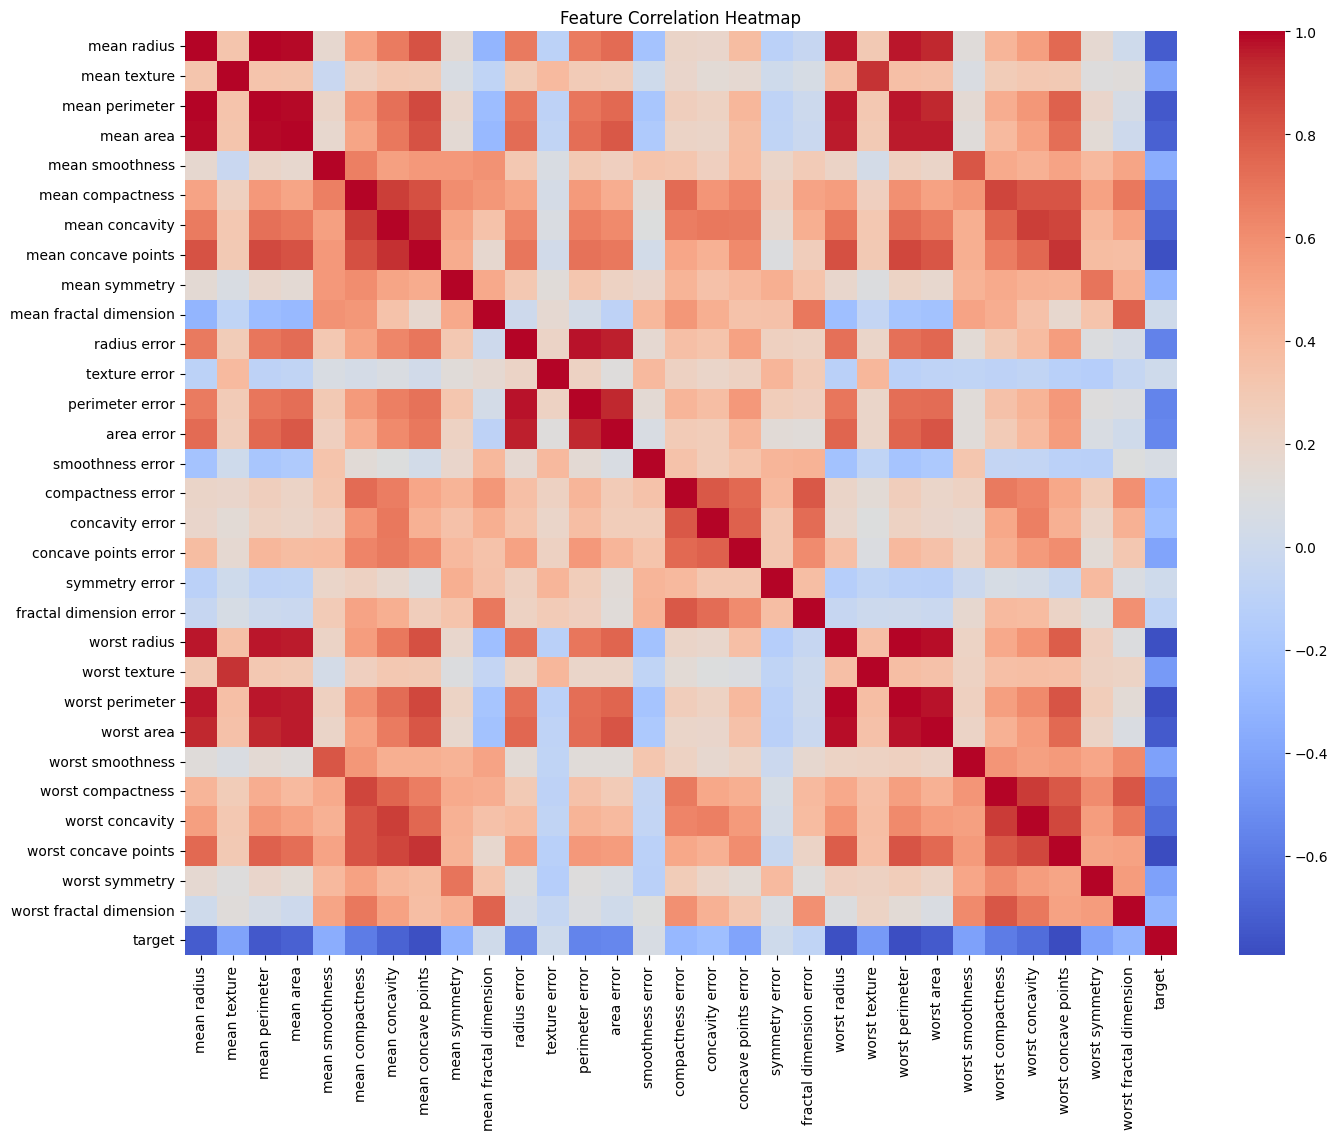

In [5]:

# Correlation Heatmap

plt.figure(figsize=(16, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [6]:

X = df.drop('target', axis=1)
y = df['target']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [9]:


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")


Feature scaling completed successfully!


In [10]:


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score

print("Machine Learning algorithms imported successfully!")


Machine Learning algorithms imported successfully!


In [11]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = {}

for name, model in models.items():

    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("----------------------------")


Logistic Regression
Accuracy: 98.25 %
----------------------------
Decision Tree
Accuracy: 91.23 %
----------------------------
Random Forest
Accuracy: 95.61 %
----------------------------


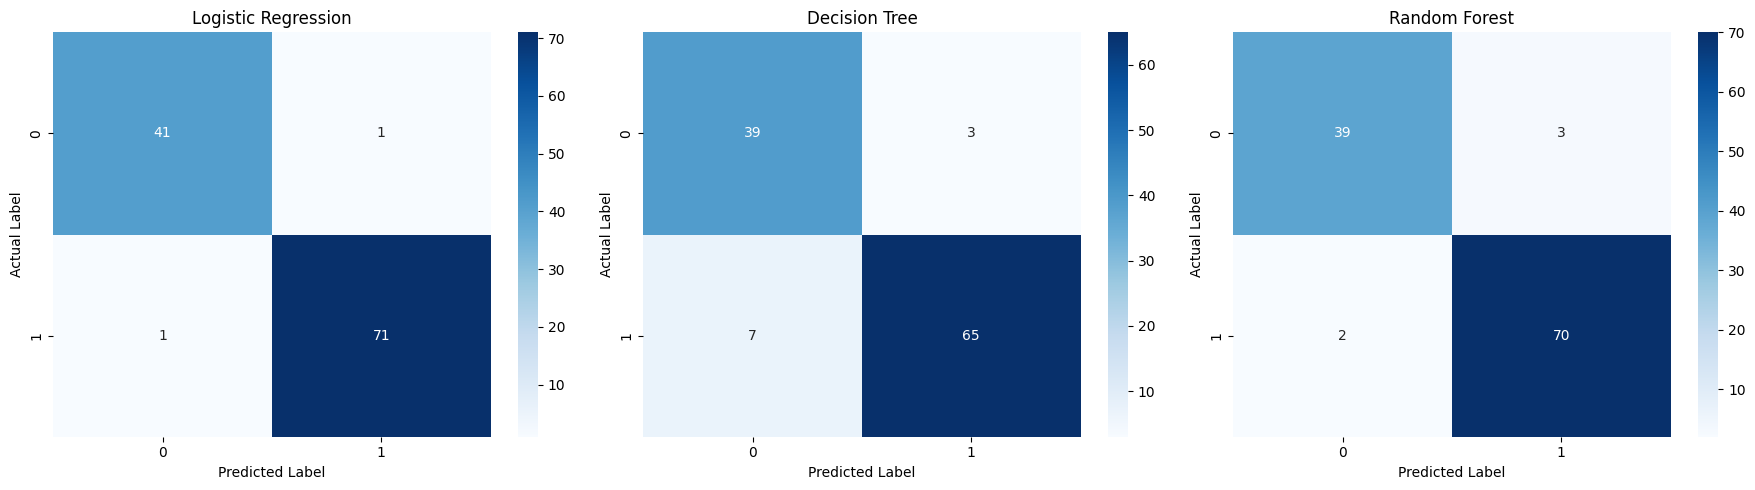

In [12]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report


predictions = {}

for name, model in models.items():

    if name == "Logistic Regression":
        predictions[name] = model.predict(X_test_scaled)
    else:
        predictions[name] = model.predict(X_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [13]:

# Classification Report for all models

for name, y_pred in predictions.items():

    print("\nModel:", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=cancer.target_names
    ))



Model: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Model: Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


Model: Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
we

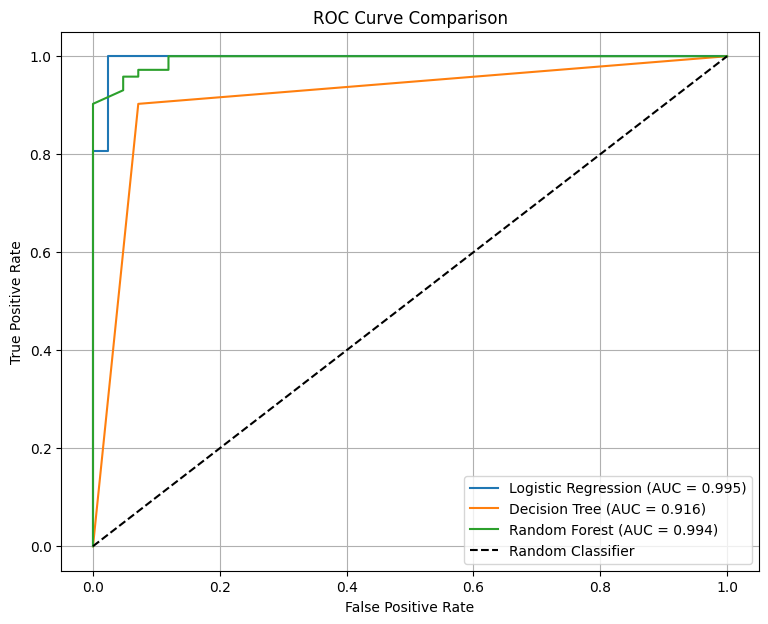

In [14]:

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

for name, model in models.items():

    if name == "Logistic Regression":
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()


In [15]:

for name, model in models.items():

    if name == "Logistic Regression":
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_prob = model.predict_proba(X_test)[:, 1]

    auc_score = roc_auc_score(y_test, y_prob)

    print(name, "AUC Score:", round(auc_score, 4))


Logistic Regression AUC Score: 0.9954
Decision Tree AUC Score: 0.9157
Random Forest AUC Score: 0.9937


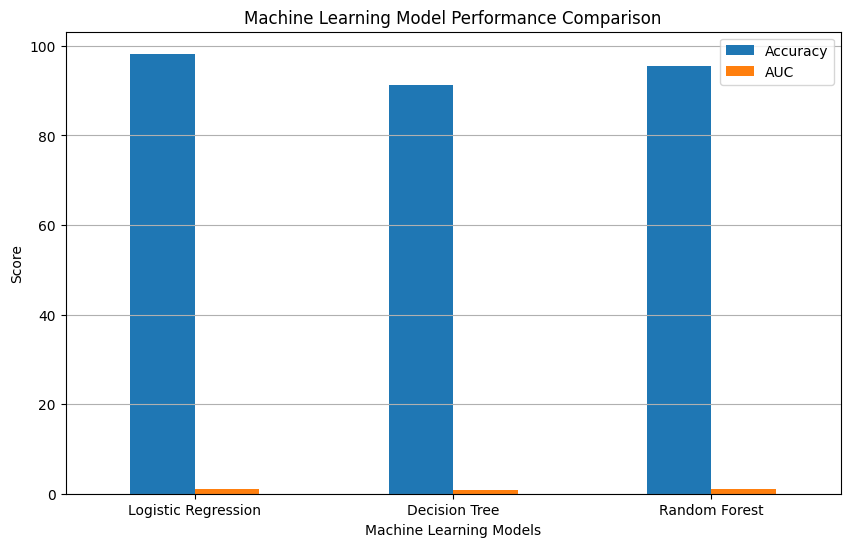

,Model,Accuracy,AUC
0,Logistic Regression,98.25,0.9954
1,Decision Tree,91.23,0.9157
2,Random Forest,95.61,0.9937


In [16]:

# Final Model Performance Comparison

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [98.25, 91.23, 95.61],
    'AUC': [0.9954, 0.9157, 0.9937]
})

comparison.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()

display(comparison)


In [17]:

comparison.to_csv("Model_Performance_Comparison.csv", index=False)

print("Model comparison results saved successfully!")


Model comparison results saved successfully!


In [18]:
from google.colab import files

files.download("Model_Performance_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>